# IPL Team Performance Analysis – Data Analytics Case Study

**Team members:** _(add names here)_
**Module:** Data Analytics

**Dataset:** IPL Complete Dataset (2008 onwards) – Kaggle, by Patrick B (`patrickb1912/ipl-complete-dataset-20082020`)
- `deliveries.csv` – one row per ball bowled (~260,000 rows, 17 columns). **This is the main dataset of the study.** Every team metric (run rate, boundaries, dot balls, economy, wickets, phase-wise scoring) is calculated from it.
- `matches.csv` – one row per match (~1,100 rows, 20 columns). Used only for context: season, winner and venue.

**Contents**
1. Business problem
2. Data understanding, cleaning & preparation
3. Exploratory data analysis (ball-by-ball)
4. Team performance profiles (batting, bowling, phases)
5. Hypothesis testing
6. Team Performance Index (rule-based, transparent)
7. Business insights
8. Recommendations

## 1. Business Problem

An IPL franchise spends crores at the auction and wants to know **where its team is strong, where it is weak, and what actually separates winning performances from losing ones**. Broadcasters and fantasy platforms need the same information to tell stories about teams and to price their products.

Win/loss alone is a poor measure of performance: a team can lose after a great batting display, or win with an average one. Ball-by-ball data lets us measure *how* a team performs, not only *whether* it won.

**Questions we want to answer**
1. How do the 10+ IPL franchises compare on batting (run rate, boundaries, dot balls) and bowling (economy, strike rate, wickets)?
2. In which phase of the innings (powerplay, middle overs, death overs) is each team strong or weak?
3. Do teams perform differently when batting first versus chasing?
4. Which on-field performance measures separate winning innings from losing ones – and are the differences statistically significant?
5. How has team performance and scoring changed over the seasons?
6. Can we build a simple, explainable **Team Performance Index** from ball-by-ball statistics, and does it agree with actual win percentage?

## 2. Data Understanding, Cleaning & Preparation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

In [2]:
# change these paths if your files are somewhere else
MATCHES_PATH = "matches.csv"
DELIVERIES_PATH = "deliveries.csv"

matches = pd.read_csv(MATCHES_PATH)
deliveries = pd.read_csv(DELIVERIES_PATH)

print("deliveries :", deliveries.shape, " <- main dataset (rows x columns)")
print("matches    :", matches.shape, " <- context only")
print()
print(deliveries.columns.tolist())

deliveries : (260920, 17)  <- main dataset (rows x columns)
matches    : (1095, 20)  <- context only

['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball', 'batter', 'bowler', 'non_striker', 'batsman_runs', 'extra_runs', 'total_runs', 'extras_type', 'is_wicket', 'player_dismissed', 'dismissal_kind', 'fielder']


In [3]:
deliveries.head()

,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,NaN,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,NaN,NaN
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN


In [4]:
deliveries.head()

,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,NaN,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,NaN,NaN
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN


In [4]:
deliveries.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260920 entries, 0 to 260919
Data columns (total 17 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   match_id          260920 non-null  int64 
 1   inning            260920 non-null  int64 
 2   batting_team      260920 non-null  object
 3   bowling_team      260920 non-null  object
 4   over              260920 non-null  int64 
 5   ball              260920 non-null  int64 
 6   batter            260920 non-null  object
 7   bowler            260920 non-null  object
 8   non_striker       260920 non-null  object
 9   batsman_runs      260920 non-null  int64 
 10  extra_runs        260920 non-null  int64 
 11  total_runs        260920 non-null  int64 
 12  extras_type       14125 non-null   object
 13  is_wicket         260920 non-null  int64 
 14  player_dismissed  12950 non-null   object
 15  dismissal_kind    12950 non-null   object
 16  fielder           9354 non-null    obj

In [6]:
# missing values in both tables
print("--- deliveries ---")
print(deliveries.isnull().sum()[deliveries.isnull().sum() > 0])
print()
print("--- matches ---")
print(matches.isnull().sum()[matches.isnull().sum() > 0])

--- deliveries ---
extras_type         246795
player_dismissed    247970
dismissal_kind      247970
fielder             251566
dtype: int64

--- matches ---
city                 51
player_of_match       5
winner                5
result_margin        19
target_runs           3
target_overs          3
method             1074
dtype: int64


**What we see**
- In `deliveries`, `extras_type`, `player_dismissed`, `dismissal_kind` and `fielder` are blank for most balls. That is normal (no extra, no wicket on that ball) and not an error.
- In `matches`, missing `winner` / `city` are mostly no-result or abandoned games.

**Key `deliveries` columns used**

| Column | Meaning | How we use it |
|---|---|---|
| `match_id`, `inning` | which match / which innings | group balls into innings |
| `batting_team`, `bowling_team` | the two sides | team-level batting and bowling metrics |
| `over` | over number | split into powerplay / middle / death phases |
| `batsman_runs`, `extra_runs`, `total_runs` | runs off the bat, extras, total | run rate, boundaries, dot balls, runs conceded |
| `extras_type` | wides, no-balls, byes, leg-byes, penalty | decide which balls are *legal* and which runs are charged to the bowler |
| `is_wicket`, `dismissal_kind` | wicket and how | wickets lost, wickets taken by bowlers |

### Cleaning steps
1. Franchises changed their names over the years, so we standardise them.
2. Make sure `over` runs from 0 to 19.
3. Keep only the two main innings (ignore super overs).
4. Keep only matches with a result, so that every innings can be labelled as a win or a loss.
5. Remove duplicate rows if any.

In [7]:
# same team, different names over the years
team_fix = {
    "Delhi Daredevils": "Delhi Capitals",
    "Kings XI Punjab": "Punjab Kings",
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
    "Rising Pune Supergiants": "Rising Pune Supergiant",
}

for col in ["team1", "team2", "toss_winner", "winner"]:
    matches[col] = matches[col].replace(team_fix)

for col in ["batting_team", "bowling_team"]:
    deliveries[col] = deliveries[col].replace(team_fix)

matches["date"] = pd.to_datetime(matches["date"])
matches["year"] = matches["date"].dt.year

# duplicates
print("duplicate matches   :", matches.duplicated().sum())
print("duplicate deliveries:", deliveries.duplicated().sum())
deliveries = deliveries.drop_duplicates()

# some versions of the file count overs from 1, we want 0-19
if deliveries["over"].min() == 1:
    deliveries["over"] = deliveries["over"] - 1

# keep only the two main innings (ignore super overs)
deliveries = deliveries[deliveries["inning"].isin([1, 2])].copy()

# matches with a result only
before = len(matches)
matches = matches[matches["winner"].notna()].copy()
print(f"dropped {before - len(matches)} matches with no winner, {len(matches)} left")

# attach season / winner / venue to every ball (this is the working ball-by-ball table)
bb = deliveries.merge(matches[["id", "year", "winner", "venue"]],
                      left_on="match_id", right_on="id", how="inner").drop(columns="id")
print("ball-by-ball rows used:", bb.shape)

duplicate matches   : 0
duplicate deliveries: 0
dropped 5 matches with no winner, 1090 left
ball-by-ball rows used: (260269, 20)


### Creating ball-level features
Cricket has some details that matter when we turn raw rows into team statistics:
- **Legal ball:** wides and no-balls do not count as one of the 6 balls in an over, so run rate is `runs / legal balls x 6`.
- **Runs charged to the bowler:** byes, leg-byes and penalty runs are *not* charged to the bowler, so economy uses a separate `bowler_runs` column.
- **Wickets credited to the bowler:** run-outs, retired and obstructing-the-field are not bowling wickets.
- **Phases:** powerplay = overs 1-6, middle = overs 7-16, death = overs 17-20.

In [8]:
bb["extras_type"] = bb["extras_type"].fillna("none")

bb["legal"] = (~bb["extras_type"].isin(["wides", "noballs"])).astype(int)
bb["illegal"] = 1 - bb["legal"]                      # wides + no-balls

# runs that count against the bowler
bb["bowler_runs"] = np.where(bb["extras_type"].isin(["byes", "legbyes", "penalty"]),
                             bb["total_runs"] - bb["extra_runs"], bb["total_runs"])

bb["is_dot"] = ((bb["total_runs"] == 0) & (bb["legal"] == 1)).astype(int)
bb["is_four"] = (bb["batsman_runs"] == 4).astype(int)
bb["is_six"] = (bb["batsman_runs"] == 6).astype(int)
bb["is_boundary"] = ((bb["batsman_runs"] == 4) | (bb["batsman_runs"] == 6)).astype(int)

not_bowler_wkt = ["run out", "retired hurt", "retired out", "obstructing the field"]
bb["bowler_wkt"] = ((bb["is_wicket"] == 1) & (~bb["dismissal_kind"].isin(not_bowler_wkt))).astype(int)

PHASES = ["Powerplay (1-6)", "Middle (7-16)", "Death (17-20)"]
bb["phase"] = pd.cut(bb["over"], bins=[-1, 5, 15, 19], labels=PHASES)

bb[["match_id", "inning", "batting_team", "bowling_team", "over", "total_runs",
    "legal", "bowler_runs", "is_dot", "is_boundary", "bowler_wkt", "phase"]].head()

,match_id,inning,batting_team,bowling_team,over,total_runs,legal,bowler_runs,is_dot,is_boundary,bowler_wkt,phase
0,335982,1,Kolkata Knight Riders,Royal Challengers Bengaluru,0,1,1,0,0,0,0,Powerplay (1-6)
1,335982,1,Kolkata Knight Riders,Royal Challengers Bengaluru,0,0,1,0,1,0,0,Powerplay (1-6)
2,335982,1,Kolkata Knight Riders,Royal Challengers Bengaluru,0,1,0,1,0,0,0,Powerplay (1-6)
3,335982,1,Kolkata Knight Riders,Royal Challengers Bengaluru,0,0,1,0,1,0,0,Powerplay (1-6)
4,335982,1,Kolkata Knight Riders,Royal Challengers Bengaluru,0,0,1,0,1,0,0,Powerplay (1-6)


### Innings-level table
One row per innings per team: runs, balls, wickets, boundaries, dot balls and run rate in each phase. We also attach the match result so every innings is labelled as part of a win or a loss. This table is the base for the hypothesis tests.

In [9]:
inn = (bb.groupby(["match_id", "inning", "batting_team", "bowling_team"])
         .agg(runs=("total_runs", "sum"), balls=("legal", "sum"), wkts=("is_wicket", "sum"),
              dots=("is_dot", "sum"), boundaries=("is_boundary", "sum"), sixes=("is_six", "sum"),
              conceded=("bowler_runs", "sum"), bowler_wkts=("bowler_wkt", "sum"),
              wd_nb=("illegal", "sum"))
         .reset_index())


def phase_stat(label, short):
    x = (bb[bb["phase"] == label].groupby(["match_id", "inning"])
           .agg(**{f"{short}_runs": ("total_runs", "sum"),
                   f"{short}_balls": ("legal", "sum"),
                   f"{short}_wkts": ("is_wicket", "sum")}))
    x[f"{short}_rr"] = x[f"{short}_runs"] / x[f"{short}_balls"] * 6
    return x


for label, short in zip(PHASES, ["pp", "mid", "death"]):
    inn = inn.merge(phase_stat(label, short), on=["match_id", "inning"], how="left")

inn = inn.merge(matches[["id", "year", "winner"]], left_on="match_id", right_on="id", how="left").drop(columns="id")

inn["won"] = (inn["batting_team"] == inn["winner"]).astype(int)
inn["run_rate"] = inn["runs"] / inn["balls"] * 6
inn["dot_pct"] = inn["dots"] / inn["balls"] * 100
inn["boundary_pct"] = inn["boundaries"] / inn["balls"] * 100

print(inn.shape)
inn[["year", "batting_team", "inning", "runs", "balls", "wkts", "run_rate", "pp_rr", "mid_rr", "death_rr", "dot_pct", "won"]].head()

(2180, 31)


,year,batting_team,inning,runs,balls,wkts,run_rate,pp_rr,mid_rr,death_rr,dot_pct,won
0,2008,Kolkata Knight Riders,1,222,120,3,11.100000,10.166667,9.700000,16.00,30.000000,1
1,2008,Royal Challengers Bengaluru,2,82,91,10,5.406593,4.333333,6.109091,NaN,54.945055,0
2,2008,Chennai Super Kings,1,240,120,5,12.000000,8.833333,11.600000,17.75,28.333333,1
3,2008,Punjab Kings,2,207,120,4,10.350000,10.500000,11.300000,7.75,19.166667,0
4,2008,Rajasthan Royals,1,129,120,8,6.450000,6.666667,6.600000,5.75,45.000000,0


In [10]:
inn[["runs", "balls", "wkts", "run_rate", "pp_rr", "mid_rr", "death_rr", "dot_pct", "boundary_pct"]].describe().round(2)

,runs,balls,wkts,run_rate,pp_rr,mid_rr,death_rr,dot_pct,boundary_pct
count,2180.00,2180.00,2180.00,2180.00,2180.00,2173.00,2036.00,2180.00,2180.00
mean,159.08,115.07,5.91,8.32,7.85,7.92,10.25,36.06,17.17
std,32.19,11.74,2.45,1.55,2.10,1.85,3.63,7.47,5.25
min,44.00,26.00,0.00,3.82,2.33,2.73,0.00,15.83,2.50
25%,139.00,116.00,4.00,7.24,6.33,6.60,8.00,30.83,13.33
50%,160.00,120.00,6.00,8.25,7.83,7.80,10.00,35.62,16.67
75%,180.00,120.00,8.00,9.30,9.17,9.00,12.32,40.68,20.58
max,287.00,121.00,10.00,17.28,20.83,16.44,36.00,68.04,51.72


## 3. Exploratory Data Analysis (ball-by-ball)

In [11]:
# the size of the data in cricket terms
print(f"Balls bowled (incl. wides/no-balls): {len(bb):,}")
print(f"Legal balls                        : {bb['legal'].sum():,}")
print(f"Runs scored                        : {bb['total_runs'].sum():,}")
print(f"Wickets fallen                     : {bb['is_wicket'].sum():,}")
print(f"Fours / Sixes                      : {bb['is_four'].sum():,} / {bb['is_six'].sum():,}")
print(f"Dot-ball share of legal balls      : {bb['is_dot'].sum() / bb['legal'].sum() * 100:.1f}%")
print(f"Overall run rate                   : {bb['total_runs'].sum() / bb['legal'].sum() * 6:.2f} runs/over")

Balls bowled (incl. wides/no-balls): 260,269
Legal balls                        : 250,845
Runs scored                        : 346,797
Wickets fallen                     : 12,893
Fours / Sixes                      : 29,770 / 13,009
Dot-ball share of legal balls      : 36.0%
Overall run rate                   : 8.30 runs/over


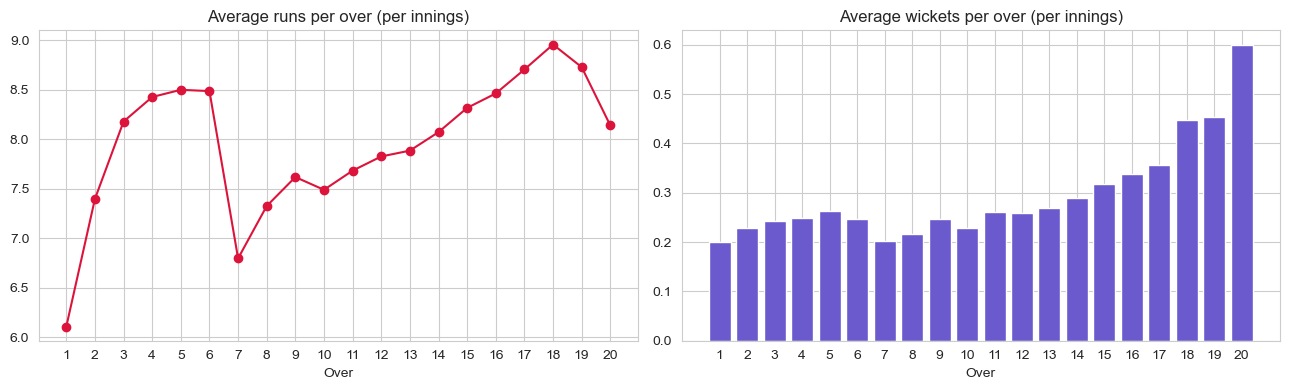

In [12]:
# runs and wickets in each over (average per innings)
n_inn = inn.shape[0]
runs_per_over = bb.groupby("over")["total_runs"].sum() / n_inn
wkts_per_over = bb.groupby("over")["is_wicket"].sum() / n_inn

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(runs_per_over.index + 1, runs_per_over.values, marker="o", color="crimson")
ax[0].set_title("Average runs per over (per innings)")
ax[0].set_xlabel("Over"); ax[0].set_xticks(range(1, 21))

ax[1].bar(wkts_per_over.index + 1, wkts_per_over.values, color="slateblue")
ax[1].set_title("Average wickets per over (per innings)")
ax[1].set_xlabel("Over"); ax[1].set_xticks(range(1, 21))
plt.tight_layout()
plt.show()